# Demo: Simulated Annealing for the TSP, blood deliveries in Cagayan de Oro City

Input: `data/*.csv`. Run with **Kernel → Restart & Run All**.

In [1]:
import itertools
import math
import random
import statistics

import folium
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

pd.set_option("display.precision", 2)

## 1 · Input data and graph

9 vertices (V0 = Red Cross depot, V1–V8 = hospitals), 72 directed arcs, weights = driving km (OpenStreetMap/OSRM).

In [2]:
locations = pd.read_csv("data/locations.csv")
matrix = pd.read_csv("data/distance_matrix.csv", index_col=0)
sources = pd.read_csv("data/data_sources.csv")

labels = list(locations.label)        # V0 .. V8
names = list(locations.short_name)    # PRC, ACE, ...
D = matrix.to_numpy().tolist()        # D[i][j] = km FROM i TO j
n = len(D)
DEPOT = 0

# Check the data before using it
assert list(matrix.index) == list(matrix.columns) == labels, "matrix labels must match locations.csv"
assert all(D[i][i] == 0 for i in range(n)), "diagonal must be 0"
assert all(D[i][j] > 0 for i in range(n) for j in range(n) if i != j), "distances must be positive"
assert len(sources) == n * (n - 1), "one source row per directed arc"
for s in sources.itertuples():
    assert matrix.loc[s.from_label, s.to_label] == s.distance_km, f"{s.from_label}->{s.to_label} differs"

print(f"{n} vertices, {n * (n - 1)} directed arcs")
print("Data status:", sources.status.value_counts().to_dict())
print("Pairs where A->B differs from B->A:",
      sum(D[i][j] != D[j][i] for i in range(n) for j in range(i + 1, n)), "of", n * (n - 1) // 2)
locations[["label", "name", "short_name", "role", "latitude", "longitude"]]

9 vertices, 72 directed arcs
Data status: {'ACTUAL': 72}
Pairs where A->B differs from B->A: 29 of 36


,label,name,short_name,role,latitude,longitude
0,V0,Philippine Red Cross Misamis Oriental-Cagayan ...,PRC,depot,8.48,124.65
1,V1,Allied Care Experts (ACE) Medical Center - Cag...,ACE,stop,8.48,124.66
2,V2,Polymedic Medical Plaza,PMP Kausw,stop,8.50,124.63
3,V3,Cagayan de Oro Polymedic General Hospital,PGH Velez,stop,8.48,124.65
4,V4,"Sabal Hospital, Inc. (Doctors Sabal Hospital)",Sabal,stop,8.49,124.65
5,V5,Maria Reyna-Xavier University Hospital,MRXUH,stop,8.48,124.66
6,V6,Madonna and Child Hospital,Madonna,stop,8.48,124.64
7,V7,Northern Mindanao Medical Center,NMMC,stop,8.49,124.65
8,V8,J.R. Borja General Hospital,JRBGH,stop,8.48,124.63


In [3]:
matrix.index.name = "FROM \\ TO (km)"
matrix.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

,V0,V1,V2,V3,V4,V5,V6,V7,V8
FROM \ TO (km),,,,,,,,,
V0,0.00,1.67,2.81,0.60,0.23,1.62,2.46,0.14,3.23
V1,1.87,0.00,4.22,2.20,1.69,1.26,4.06,1.89,4.63
V2,2.94,4.35,0.00,3.25,2.74,4.58,3.57,3.00,3.71
V3,0.82,2.36,3.37,0.00,0.73,1.96,1.85,1.03,2.37
V4,0.23,1.68,2.63,0.51,0.00,1.91,2.37,0.29,3.05
V5,1.66,1.21,4.48,1.63,1.95,0.00,2.71,1.63,3.22
V6,2.43,4.01,3.35,1.85,2.33,2.62,0.00,2.62,1.00
V7,0.14,1.62,2.87,0.80,0.29,1.62,2.66,0.00,3.29
V8,3.23,4.65,3.63,2.37,3.03,3.21,1.04,3.29,0.00


The dataset on the real map (hover a line for both directions, click a marker for its distances):

In [4]:
from src.config import DATA_DIR            # map helper only; the algorithm below does not use src/
from src.data_loader import load_dataset
from src.maps import build_dataset_map

build_dataset_map(load_dataset(DATA_DIR), D)

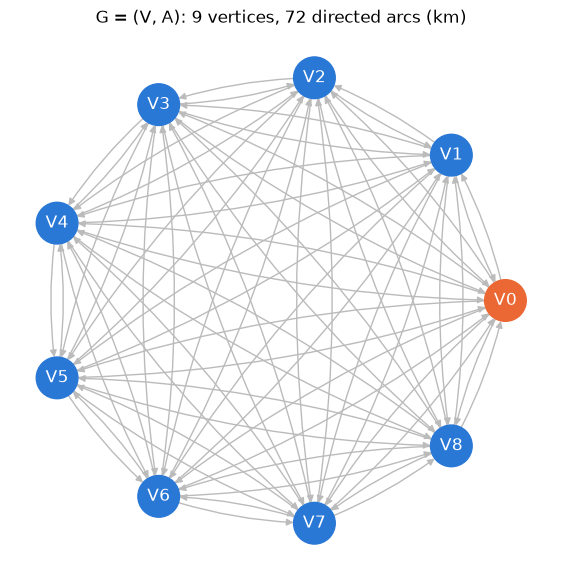

In [5]:
G = nx.DiGraph()
for i in range(n):
    for j in range(n):
        if i != j:
            G.add_edge(i, j, weight=D[i][j])

pos = nx.circular_layout(G)
plt.figure(figsize=(7, 7))
nx.draw_networkx(G, pos, labels={v: labels[v] for v in G}, node_size=900, font_color="white",
                 node_color=["#eb6834" if v == DEPOT else "#2a78d6" for v in G],
                 edge_color="#bbbbbb", arrowsize=10, connectionstyle="arc3,rad=0.08")
plt.title(f"G = (V, A): {G.number_of_nodes()} vertices, {G.number_of_edges()} directed arcs (km)")
plt.axis("off")
plt.show()

## 2 · The SA code

Tour = list of vertices with the depot fixed first. Comments give the Algorithm 2.5 step numbers.

In [6]:
def tour_cost(tour, D):
    """Alg 2.5 steps 2 and 5: total km of the closed tour, including the return to the start."""
    total = 0.0
    for k in range(len(tour) - 1):
        total += D[tour[k]][tour[k + 1]]
    return total + D[tour[-1]][tour[0]]


def random_tour(n, rng):
    """Alg 2.5 step 2: the depot first, then the hospitals in random order."""
    hospitals = list(range(1, n))
    rng.shuffle(hospitals)
    return [DEPOT] + hospitals


def swap_two_cities(tour, rng):
    """Alg 2.5 step 4: swap two hospitals (position 0, the depot, never moves)."""
    i, j = rng.sample(range(1, len(tour)), 2)
    new = tour.copy()
    new[i], new[j] = new[j], new[i]
    return new, (i, j)


def metropolis(delta, T, rng):
    """Alg 2.5 steps 6-10: a shorter tour is always accepted; a longer one with P = e^(-delta/T).
    Returns (accepted, P, r); r is drawn only when the new tour is not shorter."""
    if delta < 0:
        return True, 1.0, None
    p = math.exp(-delta / T)
    r = rng.random()
    return r < p, p, r

Step 3: $T_0$ is chosen so that an average worse move is accepted with $P = 0.8$.

In [7]:
def calibrate_t0(D, target_p=0.8, samples=2000, seed=2024):
    """Average uphill delta of random swaps, turned into T0 (km). Fixed seed -> same T0 every run."""
    rng = random.Random(seed)
    uphill = []
    for _ in range(samples):
        tour = random_tour(len(D), rng)
        new, _ = swap_two_cities(tour, rng)
        delta = tour_cost(new, D) - tour_cost(tour, D)
        if delta > 0:
            uphill.append(delta)
    mean_uphill = statistics.fmean(uphill)
    return round(-mean_uphill / math.log(target_p), 2), mean_uphill

In [8]:
def simulated_annealing(D, T0, alpha=0.98, moves_per_T=200, T_stop=0.001,
                        patience=228, max_moves=2_000_000, seed=1, trace_steps=0):
    rng = random.Random(seed)

    current = random_tour(len(D), rng)                     # step 2
    current_cost = tour_cost(current, D)
    best, best_cost = current.copy(), current_cost         # best tour seen so far
    T = T0                                                 # step 3
    moves, levels, stale = 0, 0, 0
    trace, history = [], {"current": [], "best": [], "T": []}

    while T > T_stop:                                      # step 12: stop when T is low
        best_before = best_cost
        for _ in range(moves_per_T):                       # inner loop (Appendix 4.5)
            new, swapped = swap_two_cities(current, rng)   # step 4
            new_cost = tour_cost(new, D)                   # step 5
            delta = new_cost - current_cost
            accepted, p, r = metropolis(delta, T, rng)     # steps 6-10
            if len(trace) < trace_steps:
                trace.append(dict(T=T, current=current, current_cost=current_cost, swapped=swapped,
                                  new=new, new_cost=new_cost, delta=delta, P=p, r=r, accepted=accepted))
            if accepted:
                current, current_cost = new, new_cost
                if current_cost < best_cost:
                    best, best_cost = current.copy(), current_cost
            moves += 1
            history["current"].append(current_cost)
            history["best"].append(best_cost)
            history["T"].append(T)
            if moves >= max_moves:                         # step 12: move cap
                break
        if moves >= max_moves:
            break
        T *= alpha                                         # step 11: cool
        levels += 1
        stale = 0 if best_before - best_cost > 1e-9 else stale + 1
        if stale >= patience:                              # step 12: no improvement
            break

    return dict(best=best, cost=best_cost, moves=moves, levels=levels,  # step 13
                trace=trace, history=history)

## 3 · Run SA on our graph

$\alpha = 0.98$ · 200 moves per temperature · $T_{stop} = 0.001$ km · patience 228 levels · seed 1

In [9]:
T0, mean_uphill = calibrate_t0(D)
print(f"average worse move = {mean_uphill:.2f} km  ->  T0 = {T0} km")

average worse move = 1.47 km  ->  T0 = 6.61 km


The first 5 moves: accept if $\Delta < 0$, otherwise accept if $r < P = e^{-\Delta/T}$.

In [10]:
def show(tour):
    return " → ".join(labels[v] for v in tour + [DEPOT])

res = simulated_annealing(D, T0, seed=1, trace_steps=5)

for k, s in enumerate(res["trace"], start=1):
    i, j = sorted(s["swapped"])
    print(f"Move {k}  (T = {s['T']:.4f} km)   swap positions {i} and {j}")
    print(f"  current: {show(s['current'])} = {s['current_cost']:.2f} km")
    print(f"  new    : {show(s['new'])} = {s['new_cost']:.2f} km")
    print(f"  Δ = {s['delta']:+.2f} km", end="  ")
    if s["delta"] < 0:
        print("→ shorter → ACCEPT")
    else:
        verdict = "ACCEPT the worse tour" if s["accepted"] else "REJECT"
        print(f"P = e^(-Δ/T) = {s['P']:.4f}   r = {s['r']:.4f}   → {verdict}")

Move 1  (T = 6.6100 km)   swap positions 6 and 8
  current: V0 → V4 → V7 → V2 → V6 → V8 → V1 → V5 → V3 → V0 = 16.32 km
  new    : V0 → V4 → V7 → V2 → V6 → V8 → V3 → V5 → V1 → V0 = 15.37 km
  Δ = -0.95 km  → shorter → ACCEPT
Move 2  (T = 6.6100 km)   swap positions 7 and 8
  current: V0 → V4 → V7 → V2 → V6 → V8 → V3 → V5 → V1 → V0 = 15.37 km
  new    : V0 → V4 → V7 → V2 → V6 → V8 → V3 → V1 → V5 → V0 = 15.61 km
  Δ = +0.24 km  P = e^(-Δ/T) = 0.9643   r = 0.2100   → ACCEPT the worse tour
Move 3  (T = 6.6100 km)   swap positions 1 and 8
  current: V0 → V4 → V7 → V2 → V6 → V8 → V3 → V1 → V5 → V0 = 15.61 km
  new    : V0 → V5 → V7 → V2 → V6 → V8 → V3 → V1 → V4 → V0 = 17.34 km
  Δ = +1.73 km  P = e^(-Δ/T) = 0.7697   r = 0.8933   → REJECT
Move 4  (T = 6.6100 km)   swap positions 4 and 7
  current: V0 → V4 → V7 → V2 → V6 → V8 → V3 → V1 → V5 → V0 = 15.61 km
  new    : V0 → V4 → V7 → V2 → V1 → V8 → V3 → V6 → V5 → V0 = 20.87 km
  Δ = +5.26 km  P = e^(-Δ/T) = 0.4512   r = 0.6074   → REJECT
Move 5  

In [11]:
route = res["best"] + [DEPOT]
print("Best tour :", show(res["best"]))
print("Names     :", " → ".join(names[v] for v in route))
print(f"TOTAL     : {res['cost']:.2f} km")
print(f"Moves     : {res['moves']:,} over {res['levels']} temperature levels")

Best tour : V0 → V7 → V1 → V5 → V3 → V6 → V8 → V2 → V4 → V0
Names     : PRC → NMMC → ACE → MRXUH → PGH Velez → Madonna → JRBGH → PMP Kausw → Sabal → PRC
TOTAL     : 14.10 km
Moves     : 56,200 over 281 temperature levels


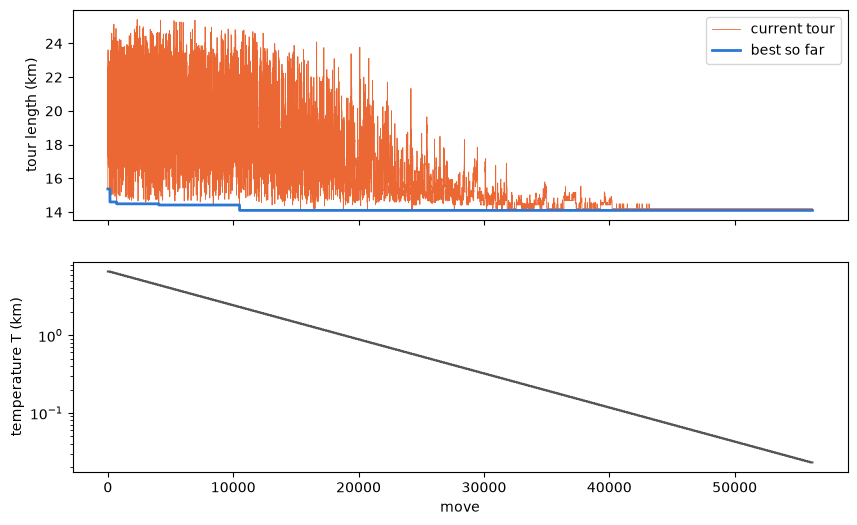

In [12]:
h = res["history"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(h["current"], lw=0.6, color="#eb6834", label="current tour")
ax1.plot(h["best"], lw=2, color="#2a78d6", label="best so far")
ax1.set_ylabel("tour length (km)")
ax1.legend()
ax2.plot(h["T"], color="#555555")
ax2.set_yscale("log")
ax2.set_ylabel("temperature T (km)")
ax2.set_xlabel("move")
plt.show()

## 4 · Verification: valid closed tour, total recounted edge by edge

In [13]:
assert route[0] == route[-1] == DEPOT, "must start and end at the depot"
assert len(route) == n + 1, "n + 1 entries"
assert sorted(route[1:-1]) == list(range(1, n)), "every hospital exactly once"

rows, running = [], 0.0
for step, (a, b) in enumerate(zip(route, route[1:]), start=1):
    km = G[a][b]["weight"]
    running += km
    rows.append([step, f"{labels[a]} {names[a]}", f"{labels[b]} {names[b]}", km, running])
display(pd.DataFrame(rows, columns=["step", "from", "to", "km", "running km"]).set_index("step"))

assert math.isclose(running, res["cost"]), "recomputed total must equal SA's total"
print(f"Recomputed {running:.2f} km = SA reported {res['cost']:.2f} km  ->  PASS")

,from,to,km,running km
step,,,,
1,V0 PRC,V7 NMMC,0.14,0.14
2,V7 NMMC,V1 ACE,1.62,1.76
3,V1 ACE,V5 MRXUH,1.26,3.02
4,V5 MRXUH,V3 PGH Velez,1.63,4.65
5,V3 PGH Velez,V6 Madonna,1.85,6.50
6,V6 Madonna,V8 JRBGH,1.00,7.50
7,V8 JRBGH,V2 PMP Kausw,3.63,11.13
8,V2 PMP Kausw,V4 Sabal,2.74,13.87
9,V4 Sabal,V0 PRC,0.23,14.10


Recomputed 14.10 km = SA reported 14.10 km  ->  PASS


In [14]:
m = folium.Map(location=[locations.latitude.mean(), locations.longitude.mean()], zoom_start=14)
points = [(locations.latitude[v], locations.longitude[v]) for v in route]
folium.PolyLine(points, color="#2a78d6", weight=4).add_to(m)
for order, v in enumerate(route[:-1]):
    colour = "#eb6834" if v == DEPOT else "#2a78d6"
    folium.Marker(points[order], tooltip=f"{labels[v]} {locations.name[v]}",
                  icon=folium.DivIcon(html=f'<div style="background:{colour};color:white;border-radius:50%;'
                                           f'width:26px;height:26px;line-height:26px;text-align:center;'
                                           f'font:bold 14px sans-serif">{"D" if v == DEPOT else order}</div>')
                  ).add_to(m)
m

## 5 · Is it optimal? Brute force over all $(n-1)! = 40{,}320$ tours, plus greedy

In [15]:
all_costs = {}
for perm in itertools.permutations(range(1, n)):            # every order of the hospitals
    all_costs[(DEPOT, *perm)] = tour_cost([DEPOT, *perm], D)
optimum = min(all_costs.values())
optimal_tours = [t for t, c in all_costs.items() if math.isclose(c, optimum)]

greedy = [DEPOT]                                             # always drive to the nearest unvisited
while len(greedy) < n:
    here = greedy[-1]
    greedy.append(min((j for j in range(n) if j not in greedy), key=lambda j: D[here][j]))

print(f"Tours checked        : {len(all_costs):,}")
print(f"Brute-force optimum  : {optimum:.2f} km  ({len(optimal_tours)} optimal tour(s)): {show(list(optimal_tours[0]))}")
print(f"Simulated Annealing  : {res['cost']:.2f} km")
print(f"Greedy               : {tour_cost(greedy, D):.2f} km: {show(greedy)}")
print(f"Average random tour  : {statistics.fmean(all_costs.values()):.2f} km")
print("SA route is OPTIMAL for this instance" if math.isclose(res["cost"], optimum)
      else f"SA route is {res['cost'] - optimum:.2f} km above the optimum")

Tours checked        : 40,320
Brute-force optimum  : 14.10 km  (1 optimal tour(s)): V0 → V7 → V1 → V5 → V3 → V6 → V8 → V2 → V4 → V0
Simulated Annealing  : 14.10 km
Greedy               : 15.37 km: V0 → V7 → V4 → V3 → V6 → V8 → V5 → V1 → V2 → V0
Average random tour  : 20.79 km
SA route is OPTIMAL for this instance


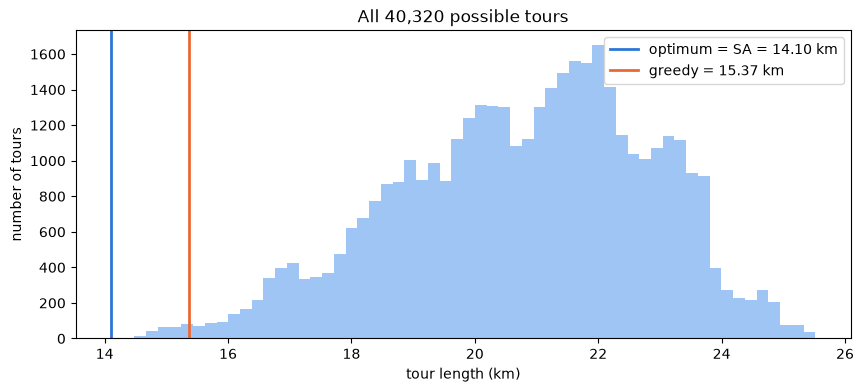

In [16]:
plt.figure(figsize=(10, 4))
plt.hist(list(all_costs.values()), bins=60, color="#9ec5f4")
plt.axvline(optimum, color="#2a78d6", lw=2, label=f"optimum = SA = {optimum:.2f} km")
plt.axvline(tour_cost(greedy, D), color="#eb6834", lw=2, label=f"greedy = {tour_cost(greedy, D):.2f} km")
plt.xlabel("tour length (km)")
plt.ylabel("number of tours")
plt.title(f"All {len(all_costs):,} possible tours")
plt.legend()
plt.show()

SA with 30 different seeds:

In [17]:
runs = [simulated_annealing(D, T0, seed=s)["cost"] for s in range(1, 31)]
hits = sum(math.isclose(c, optimum) for c in runs)
pd.DataFrame({"best km": [min(runs)], "worst km": [max(runs)], "average km": [statistics.fmean(runs)],
              "std dev": [statistics.stdev(runs)], "reached optimum": [f"{hits}/30"]}, index=["SA, 30 runs"])

,best km,worst km,average km,std dev,reached optimum
"SA, 30 runs",14.1,14.1,14.1,0.0,30/30
